# Multi-Fidelity Surrogate Model Comparison

This notebook runs all of the test cases and compares them in a single data set.

### Initialization

Add the Surrogate Modeling module and setup the notebook

In [1]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
print(module_path)
module_path = os.path.abspath(os.path.join('examples')) # or the path to your source code
sys.path.append(module_path)
print(module_path)

import torch
DEVICE='cpu'
DTYPE=torch.float64
import numpy as np


c:\Users\troyz\GitProjects\SurrogateModeling2\examples\SurrogateModels
c:\Users\troyz\GitProjects\SurrogateModeling2\examples\examples


## Example Function Introduction

Here are the analytical example toy problems for testing initial fit for multi-fidelity functions

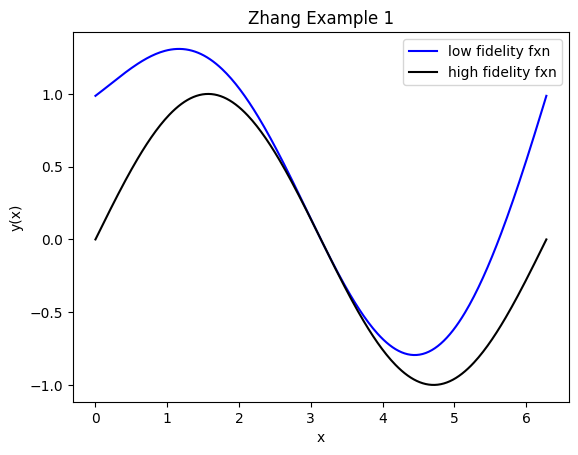

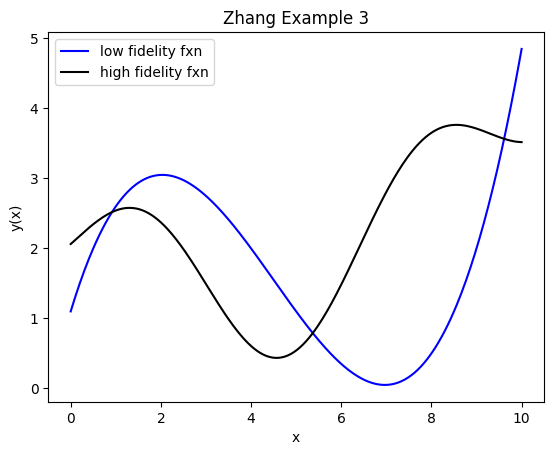

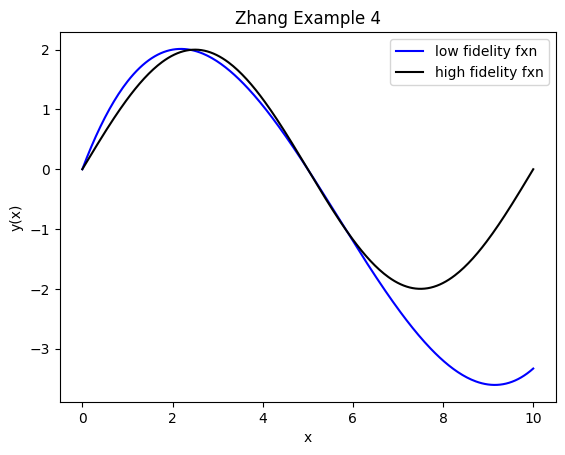

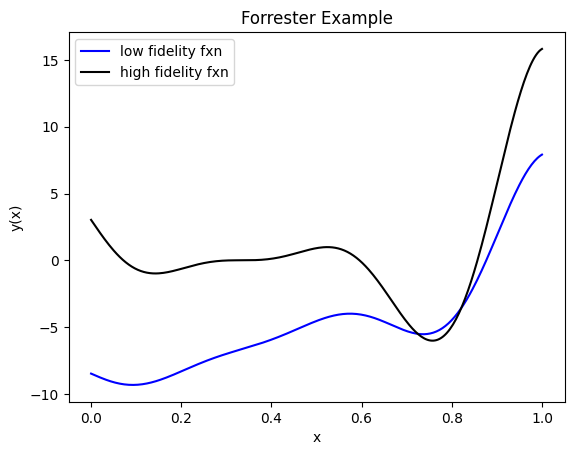

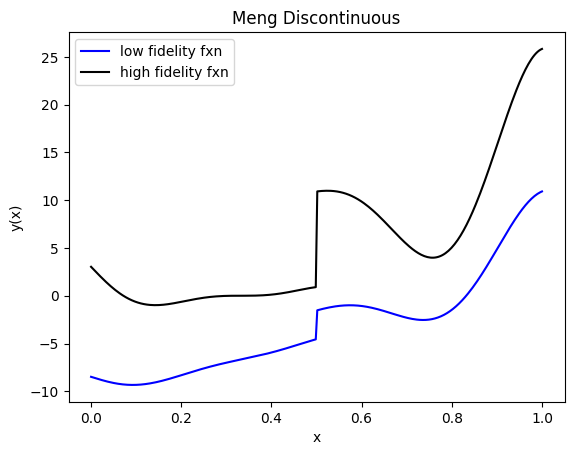

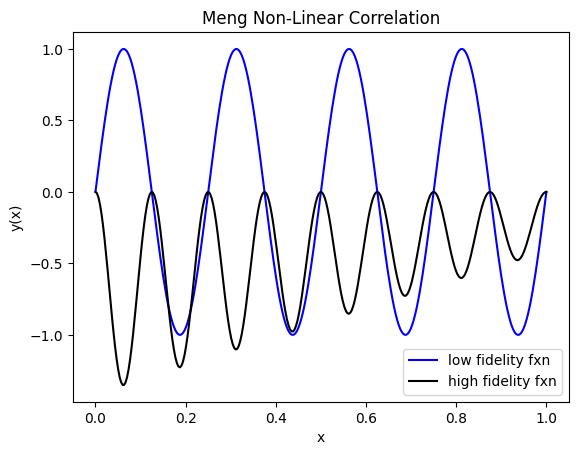

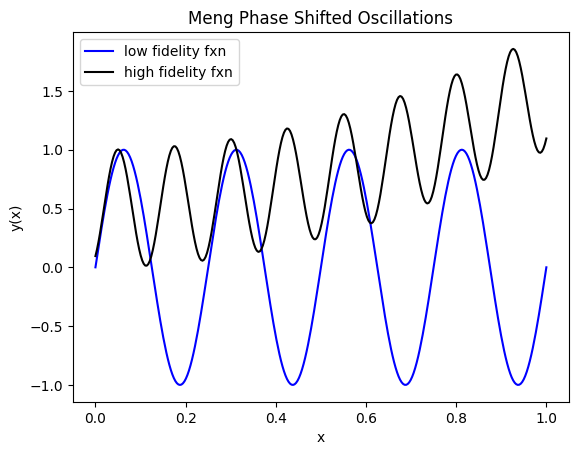

In [ ]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

for mf_example in multi_fidelity_functions.multi_fidelity_functions.values():
    current_example = mf_example()
    current_example.plot_functions_1d(name = current_example.name)
    plt.show()

# meng_example = multi_fidelity_functions.MengDiscontinuous()
# meng_example.plot_functions_1d(name = "Meng Discontinuous")
# plt.show()

### Forrester Function Fit

Fits the continuous example from the Forrester paper.

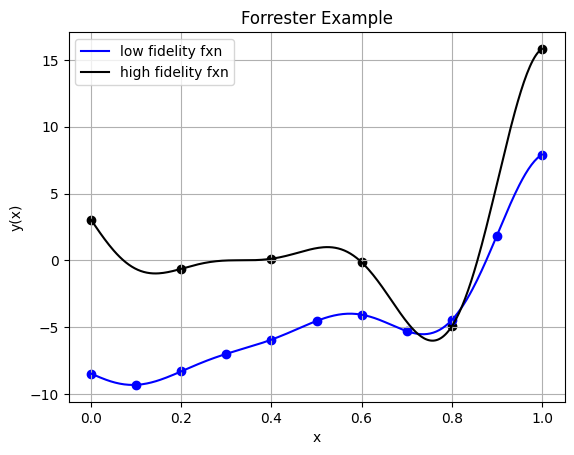

In [6]:
# Generate example data here

import numpy as np

forrester_example = multi_fidelity_functions.ForresterExample()
dim = forrester_example.dimensions
xmin = forrester_example.bounds[0][0]
xmax = forrester_example.bounds[0][1]

n_lf = 11
n_hf = 6
n_test = 40

# Generate the analytical functions
hf_fxn = forrester_example.high_fidelity
lf_fxn = forrester_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = forrester_example.name

forrester_example.plot_functions_1d(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



In [5]:
from SurrogateModels import mfsnn

# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

forrester_mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_linear_nn_dim=[10],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

tensor([[0.0000],
        [0.1000],
        [0.2000],
        [0.3000],
        [0.4000],
        [0.5000],
        [0.6000],
        [0.7000],
        [0.8000],
        [0.9000],
        [1.0000]])
----Progress Update----
Epoch: 0 

Training Error: 2.9477341175079346 

----Progress Update----
Epoch: 1 

Training Error: 2.4261484146118164 

----Progress Update----
Epoch: 2 

Training Error: 1.529853105545044 

----Progress Update----
Epoch: 3 

Training Error: 0.9649929404258728 

----Progress Update----
Epoch: 4 

Training Error: 0.7281537652015686 

----Progress Update----
Epoch: 5 

Training Error: 0.636056661605835 

----Progress Update----
Epoch: 6 

Training Error: 0.5629416704177856 

----Progress Update----
Epoch: 7 

Training Error: 0.5095089077949524 

----Progress Update----
Epoch: 8 

Training Error: 0.46514514088630676 

----Progress Update----
Epoch: 9 

Training Error: 0.411500483751297 

----Progress Update----
Epoch: 10 

Training Error: 0.33337342739105225 

----Progr

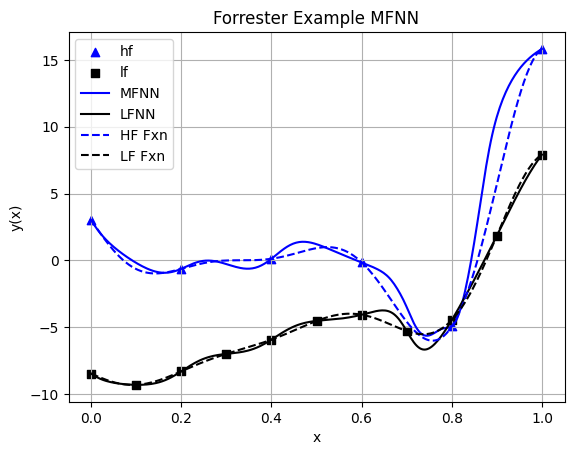

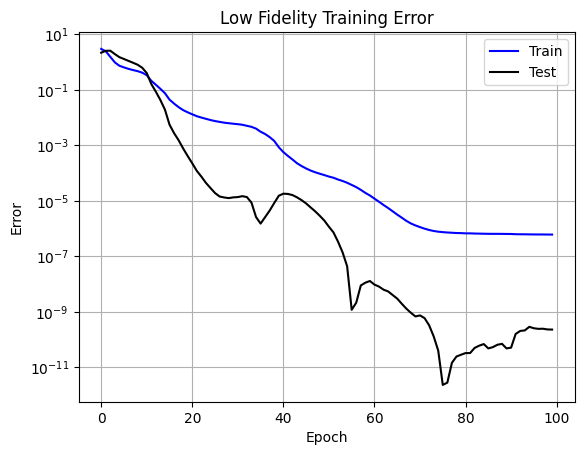

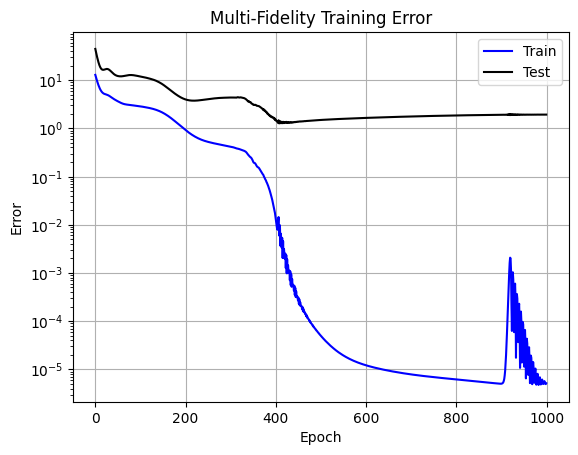

In [6]:
# Plot the results
plot_name = "Forrester Example MFNN"
forrester_mfnn_model.plot_data(plot_name)
X_check = np.linspace(0, 1.0, 300, endpoint=True,dtype=np.float32).reshape(-1,1)
X_check_tensor = torch.from_numpy(X_check)
forrester_mfnn_model.plot_model(X_check_tensor, name=plot_name, color="blue", label="MFNN")
forrester_mfnn_model.low_fidelity_nn.plot_model(X_check_tensor, name=plot_name, label="LFNN")
forrester_example.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
forrester_example.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
plt.grid()
plt.show()

# Plot the model error
forrester_mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
forrester_mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

In [7]:
from SurrogateModels import cokriging

forrester_cokriging_model = cokriging.CoKriging(X_lf,y_lf,X_hf,y_hf,True)

Optimization terminated successfully.
         Current function value: 4.877689
         Iterations: 21
         Function evaluations: 42
[16.08862305]
Optimization terminated successfully.
         Current function value: 3.296235
         Iterations: 18
         Function evaluations: 36
Optimization terminated successfully.
         Current function value: 11.254339
         Iterations: 32
         Function evaluations: 86
[1062.]


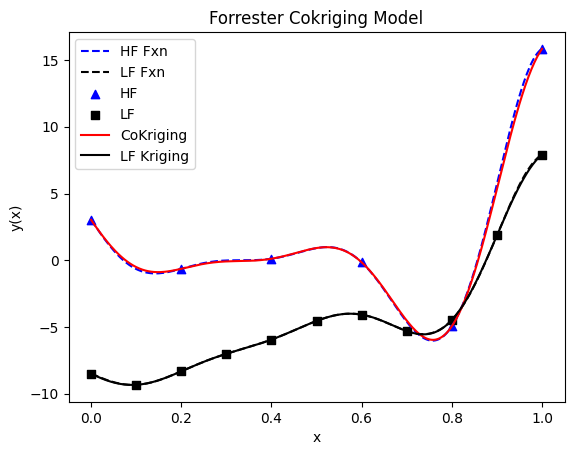

In [8]:
plot_name = "Forrester Cokriging Model"

forrester_example.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
forrester_example.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
forrester_cokriging_model.plot_data(
    name=plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
forrester_cokriging_model.plot_model(
    X_check, name=plot_name, color="red", label="CoKriging", linestyle="solid"
)
forrester_cokriging_model.kriging_lf.plot_model(
    X_check, name=plot_name, color="black", label="LF Kriging", linestyle="solid"
)
plt.show()

### Zhang Example 1 Function Fit

Fits example 1 from the Zhang 2022 paper that compares a sine function as the high fidelity to a sin function with a quadratic addition as the low fidelity.  
Sampling is done in equal spacing and features 11 low fidelity samples and 6 high fidelity.

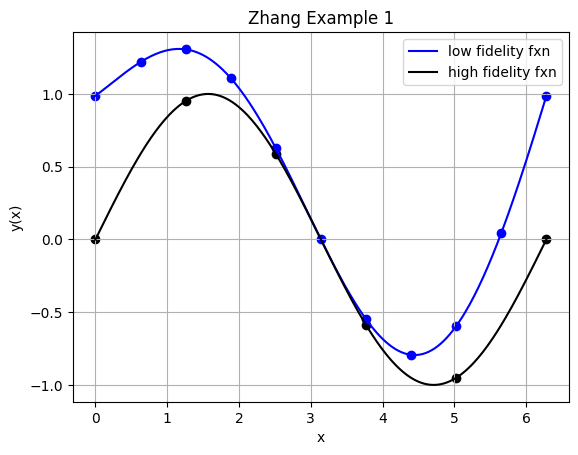

In [9]:
# Generate example data here

import numpy as np

zhang_example_1 = multi_fidelity_functions.ZhangExample1()
dim = zhang_example_1.dimensions
xmin = zhang_example_1.bounds[0][0]
xmax = zhang_example_1.bounds[0][1]

n_lf = 11
n_hf = 6
n_test = 40

# Generate the analytical functions
hf_fxn = zhang_example_1.high_fidelity
lf_fxn = zhang_example_1.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = zhang_example_1.name

zhang_example_1.plot_functions_1d(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



Generate a multi-fidelity neural network of the dataset. Follows the paper by Meng on composite neural networks.

In [10]:
from SurrogateModels import mfsnn

# Convert to tensors here
X_lf_tensor = torch.from_numpy(X_lf)
y_lf_tensor = torch.from_numpy(y_lf)

X_hf_tensor = torch.from_numpy(X_hf)
y_hf_tensor = torch.from_numpy(y_hf)

X_test_tensor = torch.from_numpy(X_test)
y_lf_test_tensor = torch.from_numpy(y_lf_test)
y_hf_test_tensor = torch.from_numpy(y_hf_test)

zhang1_mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf_tensor,
    y_lf=y_lf_tensor,
    X_lf_test=X_test_tensor,
    y_lf_test=y_lf_test_tensor,
    X_hf=X_hf_tensor,
    y_hf=y_hf_tensor,
    X_hf_test=X_test_tensor,
    y_hf_test=y_hf_test_tensor,
    lf_nn_dim=[20, 20, 20],
    hf_linear_nn_dim=[10],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

tensor([[0.0000],
        [0.6283],
        [1.2566],
        [1.8850],
        [2.5133],
        [3.1416],
        [3.7699],
        [4.3982],
        [5.0265],
        [5.6549],
        [6.2832]])
----Progress Update----
Epoch: 0 

Training Error: 0.05472590774297714 

----Progress Update----
Epoch: 1 

Training Error: 0.041556671261787415 

----Progress Update----
Epoch: 2 

Training Error: 0.03465227782726288 

----Progress Update----
Epoch: 3 

Training Error: 0.03065165877342224 

----Progress Update----
Epoch: 4 

Training Error: 0.027948791161179543 

----Progress Update----
Epoch: 5 

Training Error: 0.025865070521831512 

----Progress Update----
Epoch: 6 

Training Error: 0.024641871452331543 

----Progress Update----
Epoch: 7 

Training Error: 0.023875098675489426 

----Progress Update----
Epoch: 8 

Training Error: 0.023410361260175705 

----Progress Update----
Epoch: 9 

Training Error: 0.023062491789460182 

----Progress Update----
Epoch: 10 

Training Error: 0.0227486118

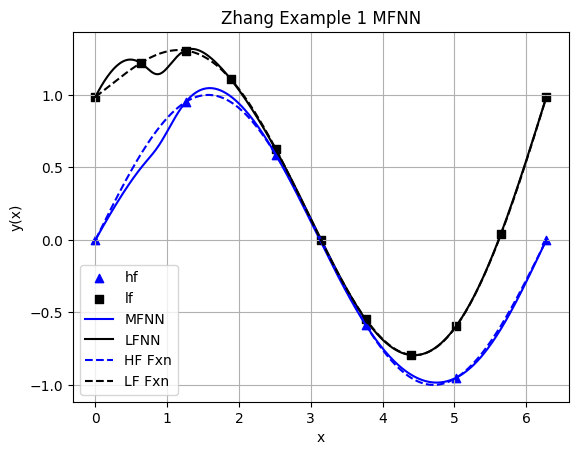

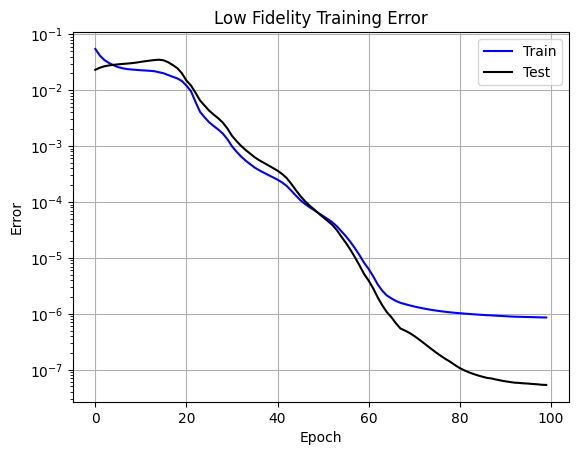

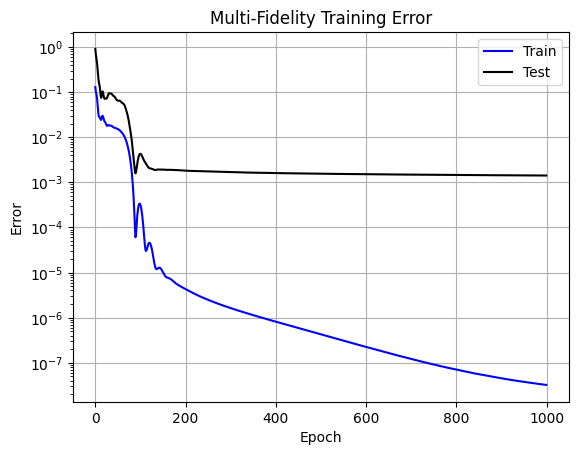

In [14]:
# Plot the results
plot_name = "Zhang Example 1 MFNN"
zhang1_mfnn_model.plot_data(plot_name)
X_check = np.linspace(0, xmax, 300, endpoint=True,dtype=np.float32).reshape(-1,1)
X_check_tensor = torch.from_numpy(X_check)
zhang1_mfnn_model.plot_model(X_check_tensor, name=plot_name, color="blue", label="MFNN")
zhang1_mfnn_model.low_fidelity_nn.plot_model(X_check_tensor, name=plot_name, label="LFNN")
zhang_example_1.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
zhang_example_1.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
plt.grid()
plt.show()

# Plot the model error
zhang1_mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
zhang1_mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

In [12]:
from SurrogateModels import cokriging

zhang1_cokriging_model = cokriging.CoKriging(X_lf,y_lf,X_hf,y_hf,True)

Optimization terminated successfully.
         Current function value: -31.901241
         Iterations: 28
         Function evaluations: 56
[0.09307861]
Optimization terminated successfully.
         Current function value: -2.593191
         Iterations: 18
         Function evaluations: 36
Optimization terminated successfully.
         Current function value: -2.626406
         Iterations: 16
         Function evaluations: 47
[40.]


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:104: RuntimeWarning: invalid value encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:193: RuntimeWarning: invalid value encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))


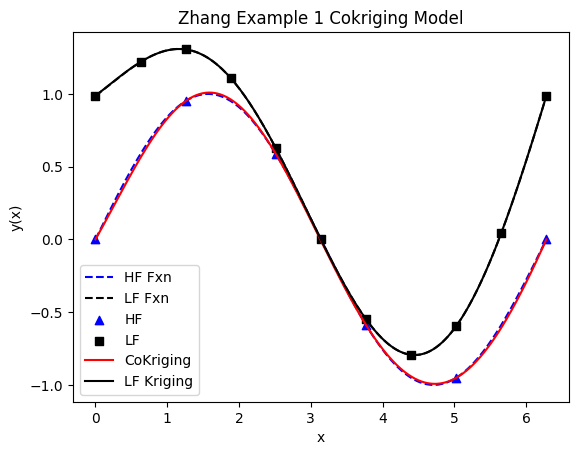

In [ ]:
plot_name = "Zhang Example 1 Cokriging Model"

zhang_example_1.plot_high_fidelity_data_1d(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
zhang_example_1.plot_low_fidelity_data_1d(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
zhang1_cokriging_model.plot_data(
    name=plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
zhang1_cokriging_model.plot_model(
    X_check, name=plot_name, color="red", label="CoKriging", linestyle="solid"
)
zhang1_cokriging_model.kriging_lf.plot_model(
    X_check, name=plot_name, color="black", label="LF Kriging", linestyle="solid"
)
plt.grid()
plt.show()